# Solving a 1D ODE with a Physics-Informed Neural Network (PINN)
### A ball thrown upwards: from-scratch NumPy (Part A) and PyTorch (Part B)

**Author:** Dishanand Jayeprokash


This notebook walks through one small, complete example of a physics-informed neural network: a ball thrown straight up, where we only have a few noisy height measurements but we also know the physics behind the motion.

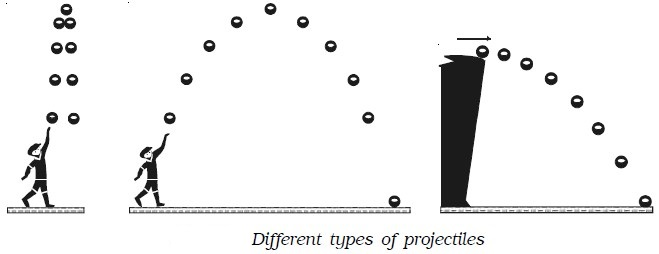

**How the notebook is organised**

| Section | What it covers |
|---|---|
| **Background** | The problem, why plain curve fitting falls short, the PINN idea, and the maths behind it |
| **Part A** | Everything written by hand with NumPy only: forward pass, derivatives, gradients, Adam optimiser |
| **Part B** | The same problem in PyTorch with automatic differentiation, followed by more advanced tools (L-BFGS, `torch.func`, loss-weight sweeps, a comparison with plain fitting) |

The idea of PINNs comes from Raissi, Perdikaris and Karniadakis (2019). The explanations, derivations, the NumPy implementation in Part A and the extra experiments in Part B are written for this notebook.

**Requirements:** Python 3.9+, `numpy`, `matplotlib`, `scipy` (Part A and Part B), `torch` (Part B only). Optional: `jupyter`.

---
# Background

## 1. The problem

We throw a ball straight up and record its height $h$ at a handful of times $t$. The measurements are not perfect: the stopwatch is imprecise, the height reading has some error, and a gust of wind might push the ball a little. So the data we get is the true trajectory plus noise.

What we want is a smooth function $h(t)$ that we can evaluate at *any* time, including times when we never measured anything.

## 2. Fitting a neural network to the data alone

The usual approach is to build a small neural network that takes $t$ as input and returns a predicted height $\hat h(t)$, then adjust its weights until the predictions are close to the measurements.

"Close" has to be turned into a single number, called the **loss**. Three obvious candidates for $N$ measurements $h_i$ and predictions $\hat h_i$:

1. **Mean of the errors**, $\frac1N\sum (h_i-\hat h_i)$. Positive and negative errors cancel, so a terrible fit can still score zero. Not useful.
2. **Mean of the absolute errors**, $\frac1N\sum |h_i-\hat h_i|$. No cancellation, but the absolute value has a kink at zero, so the derivative is not defined there.
3. **Mean of the squared errors (MSE)**, $\frac1N\sum (h_i-\hat h_i)^2$. Always non-negative and smooth everywhere. This is the standard choice.

$$
\mathcal{L}_{\text{data}} = \frac{1}{N}\sum_{i=1}^{N}\big(\hat h(t_i) - h_i\big)^2
$$

**The catch.** If one reading is far off, the network is rewarded for bending its curve to reach that bad point. A network with enough freedom can pass through every noisy point exactly, giving an MSE near zero and a curve that wiggles around the real trajectory. This is overfitting. Nothing in the loss tells the network that a ball cannot jump upwards for no reason.

## 3. The PINN idea

We usually know something about the system. A ball thrown upwards, with air drag and wind ignored, obeys Newton's second law. That law is a differential equation, and we can put it into the loss. If the network's curve breaks the equation, the loss goes up. If it respects the equation, the loss stays low.

A PINN therefore minimises a combination of:

* a **data term**: stay near the measurements,
* a **physics term**: satisfy the differential equation,
* an **initial (or boundary) condition term**: start from the right place.

## 4. The mathematics

### 4.1 The ODE and the initial condition

With only gravity acting, the acceleration is $-g$:

$$
\frac{d^2h}{dt^2} = -g .
$$

Integrating once gives the velocity, which is the derivative of height. If the launch speed is $v_0$:

$$
\frac{dh}{dt} = v_0 - g\,t .
$$

This is the first-order ODE used in the notebook. A first-order ODE needs one initial condition to pin down a unique solution, and the natural one is the starting height:

$$
h(0) = h_0 .
$$

Two balls launched at the same moment with the same upward speed but from different heights have the same $dh/dt$ and different $h(t)$. The ODE alone cannot tell them apart; the initial condition can.

### 4.2 The exact solution (our ground truth)

Integrate $dh/dt = v_0 - g t$ from $0$ to $t$ and use $h(0)=h_0$:

$$
h(t) = h_0 + \int_0^t (v_0 - g s)\,ds = h_0 + v_0 t - \tfrac12 g t^2 .
$$

We use the values $g = 9.81\ \text{m/s}^2$, $h_0 = 3\ \text{m}$, $v_0 = 9\ \text{m/s}$. The ball peaks at $t = v_0/g \approx 0.92$ s at a height of $h_0 + v_0^2/(2g) \approx 7.128$ m. We will only use this formula to generate the fake measurements and to judge the result at the end. The network never sees it directly.

### 4.3 The network as a trial function

We represent the unknown $h(t)$ by a neural network $\hat h_\theta(t)$, where $\theta$ stands for all the weights and biases. Both parts of the notebook use a network with two hidden layers of 20 neurons and a $\tanh$ activation:

$$
\mathbf a_1 = \tanh(t\,\mathbf W_1 + \mathbf b_1),\qquad
\mathbf a_2 = \tanh(\mathbf a_1 \mathbf W_2 + \mathbf b_2),\qquad
\hat h_\theta(t) = \mathbf a_2 \mathbf W_3 + \mathbf b_3 .
$$

$\tanh$ is a good fit here because it is smooth. We need to differentiate the network with respect to $t$, and a function with a kink (like ReLU) has a second derivative of zero almost everywhere, which is a poor basis for physics.

### 4.4 The three loss terms

**Data loss** (measurements $h_i$ at times $t_i$):
$$
\mathcal L_{\text{data}} = \frac1N\sum_i \big(\hat h(t_i) - h_i\big)^2
$$

**ODE loss.** The network gives us $\hat h(t)$, and we can differentiate it to get $\hat h'(t)$. Physics says that derivative should equal $v_0 - g t$:
$$
\mathcal L_{\text{ODE}} = \frac1{N}\sum_i \Big(\frac{d\hat h}{dt}\Big|_{t_i} - (v_0 - g\,t_i)\Big)^2
$$

**Initial-condition loss:**
$$
\mathcal L_{\text{IC}} = \big(\hat h(0) - h_0\big)^2
$$

### 4.5 The total loss

$$
\mathcal L(\theta) = \lambda_{\text{data}}\,\mathcal L_{\text{data}} + \lambda_{\text{ODE}}\,\mathcal L_{\text{ODE}} + \lambda_{\text{IC}}\,\mathcal L_{\text{IC}}
$$

The weights $\lambda$ say how much we trust each source of information.

* If we trust the physics completely (ball in a vacuum, nothing else going on), we can set $\lambda_{\text{data}}=0$ and the PINN becomes a plain ODE solver that needs no measurements at all.
* If the physics is only approximate (drag we ignored, wind), we keep the data term so the measurements can correct the model.
* If we trust the data completely and have no equation, we set the other two weights to zero and get ordinary curve fitting.

### 4.6 How do we get $d\hat h/dt$?

The network outputs a height, not a velocity. We get the velocity by differentiating the network with the chain rule. Writing $\odot$ for element-wise multiplication:

$$
\frac{d\mathbf a_1}{dt} = (1-\mathbf a_1^{2})\odot \mathbf W_1,\qquad
\frac{d\mathbf a_2}{dt} = (1-\mathbf a_2^{2})\odot\Big(\frac{d\mathbf a_1}{dt}\,\mathbf W_2\Big),\qquad
\frac{d\hat h}{dt} = \frac{d\mathbf a_2}{dt}\,\mathbf W_3 .
$$

This uses $\frac{d}{dz}\tanh z = 1-\tanh^2 z$. In Part A we code these formulas ourselves. In Part B, PyTorch's automatic differentiation does the same job without us writing the formulas.

### 4.7 Training

We search for the weights $\theta$ that make $\mathcal L(\theta)$ small by gradient-based optimisation. This needs $\partial\mathcal L/\partial\theta$. Because the ODE term contains $d\hat h/dt$, which itself depends on the weights, its gradient involves a derivative of a derivative. In Part A we work this out by hand and then check it against finite differences. In Part B PyTorch handles it.

---
---
# Part A: From scratch with NumPy

In this part the only libraries are NumPy (arrays and matrix maths) and Matplotlib (plots). There is no machine-learning framework. We write the forward pass, the derivative of the network with respect to time, the gradients of the loss, and the Adam optimiser ourselves.

The point is to see what a PINN actually does under the hood before handing the work to a library.

## A1. Imports
Only NumPy and Matplotlib are needed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## A2. Synthetic measurements
We fix the physics constants, define the exact solution from section 4.2, and then create 12 "measurements" between $t=0$ and $t=2$ seconds by adding Gaussian noise (standard deviation 0.7 m) to the exact heights. The random seed is fixed so the same data appears every time the notebook runs.

The data is in the form of NumPy column arrays (`reshape(-1, 1)`), because our network expects one input per row.

In [2]:
# Generate synthetic data

# Physics parameters
g = 9.81        # acceleration due to gravity
h0 = 3.0        # initial height
v0 = 9.0      # initial velocity

# true (analytical) solution h(t) = h0 + v0*t - 0.5*g*t^2
def true_solution(t):
    return h0 + v0*t - 0.5*g*(t**2)

# generate some time points
t_min, t_max = 0.0, 2.1
N_data = 12
t_data = np.linspace(t_min, t_max, N_data)

# generate synthetic "experimental" heights with noise
np.random.seed(108)
noise_level = 0.7
h_data_exact = true_solution(t_data)
h_data_noisy = h_data_exact + noise_level*np.random.randn(N_data)

# using NumPy column vectors instead of PyTorch tensors
t_col = t_data.reshape(-1, 1)
h_col = h_data_noisy.reshape(-1, 1)

Let us look at what we are working with.

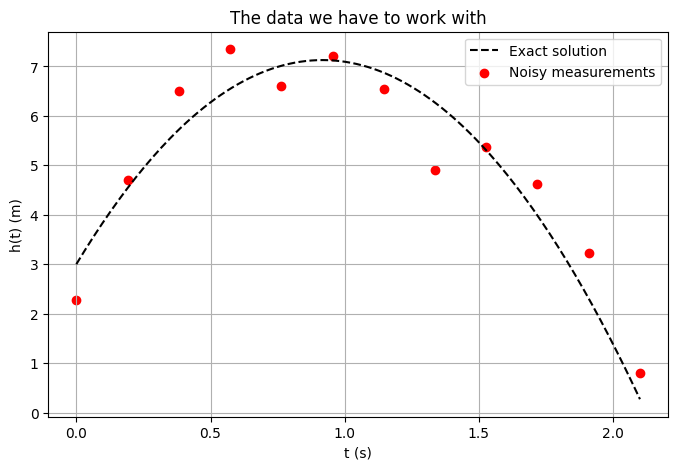

In [3]:
# plot
t_fine = np.linspace(t_min, t_max, 200)
plt.figure(figsize=(8, 5))
plt.plot(t_fine, true_solution(t_fine), 'k--', label='Exact solution')
plt.scatter(t_data, h_data_noisy, color='red', label='Noisy measurements')
plt.xlabel('t (s)')
plt.ylabel('h(t) (m)')
plt.title('The data we have to work with')
plt.legend()
plt.grid(True)
plt.show()

## A3. The network and its forward pass
The network has the shape 1 → 20 → 20 → 1 with $\tanh$ in the hidden layers (section 4.3). We store the weights in a Python dictionary.

**Initialisation.** If all weights start at zero, every neuron in a layer computes the same thing and they never become different from each other. We start with small random values instead. We use the Xavier (Glorot) uniform rule, which draws each weight from $[-a, a]$ with $a=\sqrt{6/(n_\text{in}+n_\text{out})}$. This keeps the signal at a reasonable size as it passes through the layers. Biases start at zero.

**The forward function does two jobs.** It returns the predicted height $\hat h$, and, using the formulas from section 4.6, it also returns $d\hat h/dt$. It keeps the intermediate arrays in a `cache` because we need them again when computing gradients.

In [4]:
def init_params(n_hidden=20, seed=0):
    # Xavier-uniform initial weights, zero biases
    rng = np.random.default_rng(seed)

    def layer(n_in, n_out):
        limit = np.sqrt(6.0 / (n_in + n_out))
        W = rng.uniform(-limit, limit, size=(n_in, n_out))
        b = np.zeros((1, n_out))
        return W, b

    W1, b1 = layer(1, n_hidden)
    W2, b2 = layer(n_hidden, n_hidden)
    W3, b3 = layer(n_hidden, 1)
    return {"W1": W1, "b1": b1, "W2": W2, "b2": b2, "W3": W3, "b3": b3}


def forward(params, t, with_derivative=True):
    # returns (h, dh/dt, cache). t has shape (N, 1).
    W1, b1, W2, b2, W3, b3 = (params[k] for k in ("W1", "b1", "W2", "b2", "W3", "b3"))

    # value of the network
    z1 = t @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2 + b2
    a2 = np.tanh(z2)
    h = a2 @ W3 + b3
    cache = {"t": t, "a1": a1, "a2": a2}

    # derivative with respect to t, by the chain rule (section 4.6)
    dh = None
    if with_derivative:
        s1 = 1.0 - a1**2          # tanh'(z1)
        d1 = s1 * W1            # d a1 / dt, shape (N, H)
        s2 = 1.0 - a2**2          # tanh'(z2)
        u = d1 @ W2            # d z2 / dt
        d2 = s2 * u             # d a2 / dt
        dh = d2 @ W3            # d h / dt, shape (N, 1)
        cache.update({"s1": s1, "d1": d1, "s2": s2, "u": u, "d2": d2})
    return h, dh, cache

## A4. The three loss terms
These are the formulas of section 4.4 written in NumPy. The ODE residual compares the network's derivative with the known $v_0 - g\,t$. The initial-condition term evaluates the network at $t=0$ only.

In [5]:
# losses function
def losses(params, t, h_obs, lam_data, lam_ode, lam_ic):
    h, dh, _ = forward(params, t)
    h_at_0, _, _ = forward(params, np.zeros((1, 1)), with_derivative=False)

    l_data = np.mean((h - h_obs) ** 2)        # data loss
    l_ode = np.mean((dh - (v0 - g * t)) ** 2)           # ODE loss
    l_ic = np.mean((h_at_0 - h0) ** 2)        # initial condition loss
    total = lam_data * l_data + lam_ode * l_ode + lam_ic * l_ic
    return total, l_data, l_ode, l_ic

## A5. Complete Hand-Derived Gradients

To train the network using gradient descent or L-BFGS, we require the exact partial derivatives of the scalar loss function $\mathcal{L}(\theta)$ with respect to every weight matrix and bias vector in the parameter set $\theta = \{\mathbf{W}_1, \mathbf{b}_1, \mathbf{W}_2, \mathbf{b}_2, \mathbf{W}_3, \mathbf{b}_3\}$.

---

### Variable Notation & Definitions

Before performing backpropagation, we define all state, activation, derivative, and gradient variables used throughout the network architecture:

#### Forward Value Path Variables

* $\mathbf{t} \in \mathbb{R}^{N \times 1}$: Column vector containing the batch of $N$ time inputs.


* $\mathbf{z}_1 = \mathbf{t}\mathbf{W}_1 + \mathbf{b}_1 \in \mathbb{R}^{N \times H}$: Pre-activation tensor for Layer 1, where $\mathbf{W}_1 \in \mathbb{R}^{1 \times H}$ and $\mathbf{b}_1 \in \mathbb{R}^{1 \times H}$.


* $\mathbf{a}_1 = \tanh(\mathbf{z}_1) \in \mathbb{R}^{N \times H}$: Post-activation tensor for Layer 1.


* $\mathbf{z}_2 = \mathbf{a}_1\mathbf{W}_2 + \mathbf{b}_2 \in \mathbb{R}^{N \times H}$: Pre-activation tensor for Layer 2, where $\mathbf{W}_2 \in \mathbb{R}^{H \times H}$ and $\mathbf{b}_2 \in \mathbb{R}^{1 \times H}$.


* $\mathbf{a}_2 = \tanh(\mathbf{z}_2) \in \mathbb{R}^{N \times H}$: Post-activation tensor for Layer 2.


* $\hat{h} = \mathbf{a}_2\mathbf{W}_3 + \mathbf{b}_3 \in \mathbb{R}^{N \times 1}$: Predicted output value (e.g., position height), where $\mathbf{W}_3 \in \mathbb{R}^{H \times 1}$ and $\mathbf{b}_3 \in \mathbb{R}^{1 \times 1}$.



#### Forward Time-Derivative Path Variables ($\dot{h} = \frac{d\hat{h}}{dt}$)

* $\mathbf{s}_l = \frac{d\tanh(\mathbf{z}_l)}{d\mathbf{z}_l} = 1 - \tanh^2(\mathbf{z}_l) = 1 - \mathbf{a}_l^2 \in \mathbb{R}^{N \times H}$: Slope (derivative) of the hyperbolic tangent activation function at Layer $l \in \{1, 2\}$.


* $\mathbf{d}_1 = \frac{d\mathbf{a}_1}{dt} = \mathbf{s}_1 \odot \mathbf{W}_1 \in \mathbb{R}^{N \times H}$: First-order time derivative of Layer 1 activations, where $\odot$ denotes element-wise (Hadamard) multiplication.


* $\mathbf{u} = \frac{d\mathbf{z}_2}{dt} = \mathbf{d}_1 \mathbf{W}_2 \in \mathbb{R}^{N \times H}$: First-order time derivative of Layer 2 pre-activations.


* $\mathbf{d}_2 = \frac{d\mathbf{a}_2}{dt} = \mathbf{s}_2 \odot \mathbf{u} \in \mathbb{R}^{N \times H}$: First-order time derivative of Layer 2 activations.


* $\dot{h} = \frac{d\hat{h}}{dt} = \mathbf{d}_2 \mathbf{W}_3 \in \mathbb{R}^{N \times 1}$: Predicted velocity output (explicit time derivative of the network output).



#### Backpropagation Sensitivity & Gradient Variables ($\mathbf{g}_{\phi} \equiv \frac{\partial \mathcal{L}}{\partial \phi}$)

* $\mathbf{g}_h = \frac{\partial \mathcal{L}}{\partial \hat{h}} \in \mathbb{R}^{N \times 1}$: Gradient of loss with respect to output predictions $\hat{h}$.


* $\mathbf{g}_{\dot{h}} = \frac{\partial \mathcal{L}}{\partial \dot{h}} \in \mathbb{R}^{N \times 1}$: Gradient of loss with respect to velocity predictions $\dot{h}$.


* $\mathbf{g}_{a_l} = \frac{\partial \mathcal{L}}{\partial \mathbf{a}_l} \in \mathbb{R}^{N \times H}$: Sensitivity of loss with respect to Layer $l$ post-activations $\mathbf{a}_l$.


* $\mathbf{g}_{z_l} = \frac{\partial \mathcal{L}}{\partial \mathbf{z}_l} \in \mathbb{R}^{N \times H}$: Sensitivity of loss with respect to Layer $l$ pre-activations $\mathbf{z}_l$.


* $\mathbf{g}_{d_l} = \frac{\partial \mathcal{L}}{\partial \mathbf{d}_l} \in \mathbb{R}^{N \times H}$: Sensitivity of loss with respect to time-derivative of Layer $l$ activations $\mathbf{d}_l$.


* $\mathbf{g}_u = \frac{\partial \mathcal{L}}{\partial \mathbf{u}} \in \mathbb{R}^{N \times H}$: Sensitivity of loss with respect to time-derivative of Layer 2 pre-activations $\mathbf{u}$.


* $\mathbf{g}_{s_l} = \frac{\partial \mathcal{L}}{\partial \mathbf{s}_l} \in \mathbb{R}^{N \times H}$: Sensitivity of loss with respect to activation derivative term $\mathbf{s}_l$.



---

### Component 1: Data Loss Term ($\mathcal{L}_{\text{data}}$)

The data loss measures the mean squared error between network predictions $\hat{h}(\mathbf{t}_{\text{data}})$ and observed values $h_{\text{obs}}$ over $N_{\text{data}}$ points:

$$\mathcal{L}_{\text{data}} = \lambda_{\text{data}} \frac{1}{N_{\text{data}}} \sum_{i=1}^{N_{\text{data}}} \left( \hat{h}_i - h_{\text{obs}, i} \right)^2$$

#### Step 1: Upstream Gradient at Output Prediction ($\hat{h}$)

Differentiating $\mathcal{L}_{\text{data}}$ with respect to the vector output $\hat{h}$:

$$\mathbf{g}_h = \frac{\partial \mathcal{L}_{\text{data}}}{\partial \hat{h}} = \lambda_{\text{data}} \frac{2}{N_{\text{data}}} \left( \hat{h} - h_{\text{obs}} \right) \quad \in \mathbb{R}^{N_{\text{data}} \times 1}$$

#### Step 2: Gradients for Output Layer ($\mathbf{W}_3, \mathbf{b}_3$)

Using $\hat{h} = \mathbf{a}_2 \mathbf{W}_3 + \mathbf{b}_3$, we apply the chain rule:

$$\frac{\partial \mathcal{L}_{\text{data}}}{\partial \mathbf{W}_3} = \frac{\partial \hat{h}}{\partial \mathbf{W}_3}^T \frac{\partial \mathcal{L}_{\text{data}}}{\partial \hat{h}} = \mathbf{a}_2^T \mathbf{g}_h \quad \in \mathbb{R}^{H \times 1}$$

$$\frac{\partial \mathcal{L}_{\text{data}}}{\partial \mathbf{b}_3} = \sum_{n=1}^{N_{\text{data}}} g_{h, n} = \text{sum\_rows}(\mathbf{g}_h) \quad \in \mathbb{R}^{1 \times 1}$$

#### Step 3: Backpropagation to Layer 2 Activations ($\mathbf{a}_2$)

Differentiating w.r.t. $\mathbf{a}_2$:

$$\mathbf{g}_{a_2} = \frac{\partial \mathcal{L}_{\text{data}}}{\partial \mathbf{a}_2} = \frac{\partial \mathcal{L}_{\text{data}}}{\partial \hat{h}} \frac{\partial \hat{h}}{\partial \mathbf{a}_2} = \mathbf{g}_h \mathbf{W}_3^T \quad \in \mathbb{R}^{N_{\text{data}} \times H}$$

#### Step 4: Backpropagation through Activation Function ($\tanh$) at Layer 2

Using $\mathbf{a}_2 = \tanh(\mathbf{z}_2)$ where $\frac{d\tanh(z)}{dz} = 1 - \tanh^2(z) = \mathbf{s}_2$:

$$\mathbf{g}_{z_2} = \frac{\partial \mathcal{L}_{\text{data}}}{\partial \mathbf{z}_2} = \frac{\partial \mathcal{L}_{\text{data}}}{\partial \mathbf{a}_2} \frac{\partial \mathbf{a}_2}{\partial \mathbf{z}_2} = \mathbf{g}_{a_2} \odot (1 - \mathbf{a}_2^2) = \mathbf{g}_{a_2} \odot \mathbf{s}_2 \quad \in \mathbb{R}^{N_{\text{data}} \times H}$$

#### Step 5: Gradients for Layer 2 Parameters ($\mathbf{W}_2, \mathbf{b}_2$)

Using $\mathbf{z}_2 = \mathbf{a}_1 \mathbf{W}_2 + \mathbf{b}_2$:

$$\frac{\partial \mathcal{L}_{\text{data}}}{\partial \mathbf{W}_2} = \frac{\partial \mathbf{z}_2}{\partial \mathbf{W}_2} \frac{\partial \mathcal{L}_{\text{data}}}{\partial \mathbf{z}_2} =\mathbf{a}_1^T \mathbf{g}_{z_2} \quad \in \mathbb{R}^{H \times H}$$

$$\frac{\partial \mathcal{L}_{\text{data}}}{\partial \mathbf{b}_2} = \frac{\partial \mathcal{L}_{\text{data}}}{\partial \mathbf{z}_2} \frac{\partial \mathbf{z}_2}{\partial \mathbf{b}_2} = \text{sum\_rows}(\mathbf{g}_{z_2}) \quad \in \mathbb{R}^{1 \times H}$$

#### Step 6: Backpropagation to Layer 1 Activations ($\mathbf{a}_1$)

Differentiating w.r.t. $\mathbf{a}_1$:

$$\mathbf{g}_{a_1} = \frac{\partial \mathcal{L}_{\text{data}}}{\partial \mathbf{a}_1} = \mathbf{g}_{z_2} \mathbf{W}_2^T \quad \in \mathbb{R}^{N_{\text{data}} \times H}$$

#### Step 7: Backpropagation through Activation Function ($\tanh$) at Layer 1

Using $\mathbf{a}_1 = \tanh(\mathbf{z}_1)$:

$$\mathbf{g}_{z_1} = \frac{\partial \mathcal{L}_{\text{data}}}{\partial \mathbf{z}_1} = \mathbf{g}_{a_1} \odot (1 - \mathbf{a}_1^2) = \mathbf{g}_{a_1} \odot \mathbf{s}_1 \quad \in \mathbb{R}^{N_{\text{data}} \times H}$$

#### Step 8: Gradients for Layer 1 Parameters ($\mathbf{W}_1, \mathbf{b}_1$)

Using $\mathbf{z}_1 = \mathbf{t}_{\text{data}} \mathbf{W}_1 + \mathbf{b}_1$:

$$\frac{\partial \mathcal{L}_{\text{data}}}{\partial \mathbf{W}_1} = \mathbf{t}_{\text{data}}^T \mathbf{g}_{z_1} \quad \in \mathbb{R}^{1 \times H}$$

$$\frac{\partial \mathcal{L}_{\text{data}}}{\partial \mathbf{b}_1} = \text{sum\_rows}(\mathbf{g}_{z_1}) \quad \in \mathbb{R}^{1 \times H}$$

---

### Component 2: Initial Condition Loss Term ($\mathcal{L}_{\text{ic}}$)

The initial condition loss enforces position matching at $t=0$ over $N_{\text{ic}}$ boundary points:

$$\mathcal{L}_{\text{ic}} = \lambda_{\text{ic}} \frac{1}{N_{\text{ic}}} \sum_{i=1}^{N_{\text{ic}}} \left( \hat{h}(0)_i - h_0 \right)^2$$

Because $\mathcal{L}_{\text{ic}}$ depends directly on predicted positions $\hat{h}(0)$ (and not on time derivatives $\dot{h}$), its chain rule structure is identical to the value path of $\mathcal{L}_{\text{data}}$, evaluated specifically on the initial condition inputs $\mathbf{t}_{\text{ic}} = \mathbf{0}$.

#### Step 1: Upstream Gradient at Initial Output Prediction ($\hat{h}(0)$)

$$\mathbf{g}_{h, \text{ic}} = \frac{\partial \mathcal{L}_{\text{ic}}}{\partial \hat{h}(0)} = \lambda_{\text{ic}} \frac{2}{N_{\text{ic}}} \left( \hat{h}(0) - h_0 \right) \quad \in \mathbb{R}^{N_{\text{ic}} \times 1}$$

#### Step 2: Chain Rule Backpropagation Across All Layers

1. **Layer 3 Parameters:**

$$\frac{\partial \mathcal{L}_{\text{ic}}}{\partial \mathbf{W}_3} = \mathbf{a}_2(0)^T \mathbf{g}_{h, \text{ic}}, \qquad \frac{\partial \mathcal{L}_{\text{ic}}}{\partial \mathbf{b}_3} = \text{sum\_rows}(\mathbf{g}_{h, \text{ic}})$$


2. **Layer 2 Activations & Pre-Activations:**

$$\mathbf{g}_{a_2, \text{ic}} = \mathbf{g}_{h, \text{ic}} \mathbf{W}_3^T, \qquad \mathbf{g}_{z_2, \text{ic}} = \mathbf{g}_{a_2, \text{ic}} \odot \mathbf{s}_2(0)$$


3. **Layer 2 Parameters:**

$$\frac{\partial \mathcal{L}_{\text{ic}}}{\partial \mathbf{W}_2} = \mathbf{a}_1(0)^T \mathbf{g}_{z_2, \text{ic}}, \qquad \frac{\partial \mathcal{L}_{\text{ic}}}{\partial \mathbf{b}_2} = \text{sum\_rows}(\mathbf{g}_{z_2, \text{ic}})$$


4. **Layer 1 Activations & Pre-Activations:**

$$\mathbf{g}_{a_1, \text{ic}} = \mathbf{g}_{z_2, \text{ic}} \mathbf{W}_2^T, \qquad \mathbf{g}_{z_1, \text{ic}} = \mathbf{g}_{a_1, \text{ic}} \odot \mathbf{s}_1(0)$$


5. **Layer 1 Parameters:**

$$\frac{\partial \mathcal{L}_{\text{ic}}}{\partial \mathbf{W}_1} = \mathbf{t}_{\text{ic}}^T \mathbf{g}_{z_1, \text{ic}}, \qquad \frac{\partial \mathcal{L}_{\text{ic}}}{\partial \mathbf{b}_1} = \text{sum\_rows}(\mathbf{g}_{z_1, \text{ic}})$$



---

### Component 3: ODE Residual Loss Term ($\mathcal{L}_{\text{ode}}$)

The ODE loss penalizes physics residual errors in predicted velocity $\dot{h}(t) = \frac{d\hat{h}}{dt}$ against governing kinematics $f(t) = v_0 - g t$ over $N_{\text{ode}}$ collocation points:

$$\mathcal{L}_{\text{ode}} = \lambda_{\text{ode}} \frac{1}{N_{\text{ode}}} \sum_{i=1}^{N_{\text{ode}}} \left( \dot{h}_i - (v_0 - g t_i) \right)^2$$

Because $\dot{h}$ is computed using network weights, gradients flow through the derivative operations derived in the forward time pass.

#### Step 1: Upstream Gradient at Velocity Prediction ($\dot{h}$)

$$\mathbf{g}_{\dot{h}} = \frac{\partial \mathcal{L}_{\text{ode}}}{\partial \dot{h}} = \lambda_{\text{ode}} \frac{2}{N_{\text{ode}}} \left( \dot{h} - (v_0 - g \mathbf{t}_{\text{ode}}) \right) \quad \in \mathbb{R}^{N_{\text{ode}} \times 1}$$

#### Step 2: Backpropagation through $\dot{h} = \mathbf{d}_2 \mathbf{W}_3$

1. **Direct Gradient Contribution to $\mathbf{W}_3$:**

$$\frac{\partial \mathcal{L}_{\text{ode}}}{\partial \mathbf{W}_3}_{\text{direct}} = \frac{\partial \dot{h}}{\partial \mathbf{W}_3}^T \frac{\partial \mathcal{L}_{\text{ode}}}{\partial \dot{h}} = \mathbf{d}_2^T \mathbf{g}_{\dot{h}} \quad \in \mathbb{R}^{H \times 1}$$


2. **Sensitivity w.r.t. Layer 2 Time Derivative ($\mathbf{d}_2$):**

$$\mathbf{g}_{d_2} = \frac{\partial \mathcal{L}_{\text{ode}}}{\partial \mathbf{d}_2} = \mathbf{g}_{\dot{h}} \mathbf{W}_3^T \quad \in \mathbb{R}^{N_{\text{ode}} \times H}$$



#### Step 3: Backpropagation through $\mathbf{d}_2 = \mathbf{s}_2 \odot \mathbf{u}$

Applying the matrix product rule for Hadamard (element-wise) multiplication:

1. **Sensitivity w.r.t. Pre-activation Time Derivative ($\mathbf{u}$):**

$$\mathbf{g}_u = \frac{\partial \mathcal{L}_{\text{ode}}}{\partial \mathbf{u}} = \mathbf{g}_{d_2} \odot \frac{\partial \mathbf{d}_2}{\partial \mathbf{u}} = \mathbf{g}_{d_2} \odot \mathbf{s}_2 \quad \in \mathbb{R}^{N_{\text{ode}} \times H}$$


2. **Sensitivity w.r.t. Activation Derivative Term ($\mathbf{s}_2$):**

$$\mathbf{g}_{s_2} = \frac{\partial \mathcal{L}_{\text{ode}}}{\partial \mathbf{s}_2} = \mathbf{g}_{d_2} \odot \frac{\partial \mathbf{d}_2}{\partial \mathbf{s}_2} = \mathbf{g}_{d_2} \odot \mathbf{u} \quad \in \mathbb{R}^{N_{\text{ode}} \times H}$$



#### Step 4: Backpropagation through Activation Slope $\mathbf{s}_2 = 1 - \mathbf{a}_2^2$

Differentiating $\mathbf{s}_2$ with respect to post-activations $\mathbf{a}_2$:

$$\frac{\partial \mathbf{s}_2}{\partial \mathbf{a}_2} = \frac{d}{d\mathbf{a}_2} \left( 1 - \mathbf{a}_2^2 \right) = -2 \mathbf{a}_2$$

This creates an extra gradient contribution flowing back into Layer 2 activations:

$$\mathbf{g}_{a_2, \text{extra}} = \mathbf{g}_{s_2} \odot (-2 \mathbf{a}_2) \quad \in \mathbb{R}^{N_{\text{ode}} \times H}$$

#### Step 5: Backpropagation through $\mathbf{u} = \mathbf{d}_1 \mathbf{W}_2$

1. **Direct Gradient Contribution to $\mathbf{W}_2$:**

$$\frac{\partial \mathcal{L}_{\text{ode}}}{\partial \mathbf{W}_2}_{\text{direct}} = \frac{\partial \mathbf{u}}{\partial \mathbf{W}_2}^T \frac{\partial \mathcal{L}_{\text{ode}}}{\partial \mathbf{u}} = \mathbf{d}_1^T \mathbf{g}_u \quad \in \mathbb{R}^{H \times H}$$


2. **Sensitivity w.r.t. Layer 1 Time Derivative ($\mathbf{d}_1$):**

$$\mathbf{g}_{d_1} = \frac{\partial \mathcal{L}_{\text{ode}}}{\partial \mathbf{d}_1} = \mathbf{g}_u \mathbf{W}_2^T \quad \in \mathbb{R}^{N_{\text{ode}} \times H}$$



#### Step 6: Backpropagation through $\mathbf{d}_1 = \mathbf{s}_1 \odot \mathbf{W}_1$

Because $\mathbf{W}_1 \in \mathbb{R}^{1 \times H}$ is broadcasted across $N_{\text{ode}}$ samples, $d_{1, n, j} = s_{1, n, j} W_{1, j}$:

1. **Direct Gradient Contribution to $\mathbf{W}_1$ (summed over $N_{\text{ode}}$ batch dimension):**

$$\frac{\partial \mathcal{L}_{\text{ode}}}{\partial \mathbf{W}_1}_{\text{direct}} = \sum_{n=1}^{N_{\text{ode}}} \left( \mathbf{g}_{d_1} \odot \mathbf{s}_1 \right)_{n, \cdot} = \text{sum\_rows}(\mathbf{g}_{d_1} \odot \mathbf{s}_1) \quad \in \mathbb{R}^{1 \times H}$$


2. **Sensitivity w.r.t. Activation Derivative Term ($\mathbf{s}_1$):**

$$\mathbf{g}_{s_1} = \frac{\partial \mathcal{L}_{\text{ode}}}{\partial \mathbf{s}_1} = \mathbf{g}_{d_1} \odot \mathbf{W}_1 \quad \in \mathbb{R}^{N_{\text{ode}} \times H}$$



#### Step 7: Backpropagation through Activation Slope $\mathbf{s}_1 = 1 - \mathbf{a}_1^2$

Differentiating $\mathbf{s}_1$ with respect to post-activations $\mathbf{a}_1$:

$$\mathbf{g}_{a_1, \text{extra}} = \mathbf{g}_{s_1} \odot (-2 \mathbf{a}_1) \quad \in \mathbb{R}^{N_{\text{ode}} \times H}$$

#### Step 8: Re-Injecting Extra Activations into Standard Value Backpropagation Chain

Because $\mathbf{a}_2$ and $\mathbf{a}_1$ are produced by network weights via $\mathbf{z}_2$ and $\mathbf{z}_1$, the extra activation gradients ($\mathbf{g}_{a_2, \text{extra}}$ and $\mathbf{g}_{a_1, \text{extra}}$) flow backward through the standard value path:

1. **Layer 2 Pre-Activation Gradient from ODE Path:**

$$\mathbf{g}_{z_2, \text{ode}} = \mathbf{g}_{a_2, \text{extra}} \odot (1 - \mathbf{a}_2^2) = \mathbf{g}_{a_2, \text{extra}} \odot \mathbf{s}_2$$


2. **Indirect Gradient Contributions to $\mathbf{W}_2, \mathbf{b}_2$:**

$$\frac{\partial \mathcal{L}_{\text{ode}}}{\partial \mathbf{W}_2}_{\text{indirect}} = \mathbf{a}_1^T \mathbf{g}_{z_2, \text{ode}}, \qquad \frac{\partial \mathcal{L}_{\text{ode}}}{\partial \mathbf{b}_2} = \text{sum\_rows}(\mathbf{g}_{z_2, \text{ode}})$$


3. **Merging Path Gradients at Layer 1 Activations ($\mathbf{a}_1$):**

$$\mathbf{g}_{a_1, \text{ode\_total}} = \mathbf{g}_{z_2, \text{ode}} \mathbf{W}_2^T + \mathbf{g}_{a_1, \text{extra}}$$


4. **Layer 1 Pre-Activation Gradient from ODE Path:**

$$\mathbf{g}_{z_1, \text{ode}} = \mathbf{g}_{a_1, \text{ode\_total}} \odot (1 - \mathbf{a}_1^2) = \mathbf{g}_{a_1, \text{ode\_total}} \odot \mathbf{s}_1$$


5. **Indirect Gradient Contributions to $\mathbf{W}_1, \mathbf{b}_1$:**

$$\frac{\partial \mathcal{L}_{\text{ode}}}{\partial \mathbf{W}_1}_{\text{indirect}} = \mathbf{t}_{\text{ode}}^T \mathbf{g}_{z_1, \text{ode}}, \qquad \frac{\partial \mathcal{L}_{\text{ode}}}{\partial \mathbf{b}_1} = \text{sum\_rows}(\mathbf{g}_{z_1, \text{ode}})$$



---

### Total Accumulated Network Parameter Gradients

Summing the exact partial derivatives across all three loss terms ($\mathcal{L} = \mathcal{L}_{\text{data}} + \mathcal{L}_{\text{ic}} + \mathcal{L}_{\text{ode}}$) gives the complete gradient set:

$$\begin{aligned} \frac{\partial \mathcal{L}}{\partial \mathbf{W}_3} &= \mathbf{a}_{2, \text{data}}^T \mathbf{g}_{h, \text{data}} + \mathbf{a}_{2, \text{ic}}^T \mathbf{g}_{h, \text{ic}} + \mathbf{d}_{2, \text{ode}}^T \mathbf{g}_{\dot{h}} \\ \frac{\partial \mathcal{L}}{\partial \mathbf{b}_3} &= \text{sum\_rows}(\mathbf{g}_{h, \text{data}}) + \text{sum\_rows}(\mathbf{g}_{h, \text{ic}}) \\ \frac{\partial \mathcal{L}}{\partial \mathbf{W}_2} &= \mathbf{a}_{1, \text{data}}^T \mathbf{g}_{z_2, \text{data}} + \mathbf{a}_{1, \text{ic}}^T \mathbf{g}_{z_2, \text{ic}} + \mathbf{d}_{1, \text{ode}}^T \mathbf{g}_u + \mathbf{a}_{1, \text{ode}}^T \mathbf{g}_{z_2, \text{ode}} \\ \frac{\partial \mathcal{L}}{\partial \mathbf{b}_2} &= \text{sum\_rows}(\mathbf{g}_{z_2, \text{data}}) + \text{sum\_rows}(\mathbf{g}_{z_2, \text{ic}}) + \text{sum\_rows}(\mathbf{g}_{z_2, \text{ode}}) \\ \frac{\partial \mathcal{L}}{\partial \mathbf{W}_1} &= \mathbf{t}_{\text{data}}^T \mathbf{g}_{z_1, \text{data}} + \mathbf{t}_{\text{ic}}^T \mathbf{g}_{z_1, \text{ic}} + \text{sum\_rows}(\mathbf{g}_{d_1} \odot \mathbf{s}_{1, \text{ode}}) + \mathbf{t}_{\text{ode}}^T \mathbf{g}_{z_1, \text{ode}} \\ \frac{\partial \mathcal{L}}{\partial \mathbf{b}_1} &= \text{sum\_rows}(\mathbf{g}_{z_1, \text{data}}) + \text{sum\_rows}(\mathbf{g}_{z_1, \text{ic}}) + \text{sum\_rows}(\mathbf{g}_{z_1, \text{ode}}) \end{aligned}$$

In [6]:
def _backprop_through_layers(params, cache, ga2, ga1_extra, grads):
    # shared tail of backprop: from the gradient at a2 (and any extra gradient
    # reaching a1) back to W2, b2, W1, b1.
    W2 = params["W2"]
    t, a1, a2 = cache["t"], cache["a1"], cache["a2"]

    dz2 = ga2 * (1.0 - a2**2)
    grads["W2"] += a1.T @ dz2
    grads["b2"] += dz2.sum(axis=0, keepdims=True)

    ga1 = dz2 @ W2.T + ga1_extra
    dz1 = ga1 * (1.0 - a1**2)
    grads["W1"] += t.T @ dz1
    grads["b1"] += dz1.sum(axis=0, keepdims=True)


def backprop_value_path(params, cache, gh, grads):
    # backprop for terms that depend on the network output h (data and IC losses).
    W3 = params["W3"]
    grads["W3"] += cache["a2"].T @ gh
    grads["b3"] += gh.sum(axis=0, keepdims=True)
    ga2 = gh @ W3.T
    _backprop_through_layers(params, cache, ga2, 0.0, grads)


def backprop_derivative_path(params, cache, gdh, grads):
    # backprop for terms that depend on dh/dt (the ODE loss).
    W1, W2, W3 = params["W1"], params["W2"], params["W3"]
    a1, a2 = cache["a1"], cache["a2"]
    s1, s2, d1, u, d2 = cache["s1"], cache["s2"], cache["d1"], cache["u"], cache["d2"]

    grads["W3"] += d2.T @ gdh
    gd2 = gdh @ W3.T
    gu = gd2 * s2
    gs2 = gd2 * u
    ga2 = gs2 * (-2.0 * a2)

    grads["W2"] += d1.T @ gu
    gd1 = gu @ W2.T
    grads["W1"] += (gd1 * s1).sum(axis=0, keepdims=True)
    gs1 = gd1 * W1
    ga1_extra = gs1 * (-2.0 * a1)

    _backprop_through_layers(params, cache, ga2, ga1_extra, grads)


def loss_and_grads(params, t, h_obs, lam_data, lam_ode, lam_ic, t_ode=None):
    # total loss and its gradient with respect to every parameter.
    # t      : times of the measurements (data loss)
    # t_ode  : times where the ODE is enforced; defaults to t, as in the article.
    if t_ode is None:
        t_ode = t
    grads = {k: np.zeros_like(v) for k, v in params.items()}

    h, _, cache = forward(params, t, with_derivative=False)
    _, dh, cache_ode = forward(params, t_ode)
    h_at_0, _, cache0 = forward(params, np.zeros((1, 1)), with_derivative=False)

    r_data = h - h_obs
    r_ode = dh - (v0 - g * t_ode)
    r_ic = h_at_0 - h0

    l_data, l_ode, l_ic = np.mean(r_data**2), np.mean(r_ode**2), np.mean(r_ic**2)
    total = lam_data * l_data + lam_ode * l_ode + lam_ic * l_ic

    # d(mean(r^2))/dr = 2 r / N
    backprop_value_path(params, cache, lam_data * 2.0 / t.shape[0] * r_data, grads)
    backprop_derivative_path(params, cache_ode, lam_ode * 2.0 / t_ode.shape[0] * r_ode, grads)
    backprop_value_path(params, cache0, lam_ic * 2.0 * r_ic, grads)
    return total, (l_data, l_ode, l_ic), grads

## A6. Checking the gradients with finite differences
A reliable way to test hand-written gradients is to compare them with a numerical estimate. For each parameter $\theta_k$ we nudge it up and down by a tiny amount $\varepsilon$ and measure how the loss changes (central difference):

$$
\frac{\partial\mathcal L}{\partial\theta_k}\approx\frac{\mathcal L(\theta_k+\varepsilon)-\mathcal L(\theta_k-\varepsilon)}{2\varepsilon}.
$$

If our formulas are correct, the two answers agree to many decimal places. This is slow (two loss evaluations per parameter), so it is for testing only and not used in training.

In [7]:
check_params = init_params(20, seed=1)
_, _, analytic = loss_and_grads(check_params, t_col, h_col, 2.0, 2.0, 2.0)

eps = 1e-6
worst = 0.0
for name in check_params:
    numeric = np.zeros_like(check_params[name])
    it = np.nditer(check_params[name], flags=["multi_index"])
    for _ in it:
        idx = it.multi_index
        old = check_params[name][idx]
        check_params[name][idx] = old + eps
        lp = losses(check_params, t_col, h_col, 2.0, 2.0, 2.0)[0]
        check_params[name][idx] = old - eps
        lm = losses(check_params, t_col, h_col, 2.0, 2.0, 2.0)[0]
        check_params[name][idx] = old
        numeric[idx] = (lp - lm) / (2 * eps)

    denom = np.maximum(np.abs(numeric) + np.abs(analytic[name]), 1e-12)
    rel_err = np.max(np.abs(numeric - analytic[name]) / denom)
    worst = max(worst, rel_err)
    print(f"{name}: largest relative difference = {rel_err:.2e}")

print(f"\nWorst case over all parameters: {worst:.2e}")

W1: largest relative difference = 2.52e-08
b1: largest relative difference = 7.60e-09
W2: largest relative difference = 1.27e-06
b2: largest relative difference = 4.35e-09
W3: largest relative difference = 1.04e-08
b3: largest relative difference = 1.01e-10

Worst case over all parameters: 1.27e-06


Differences at the level of $10^{-6}$ or smaller mean the analytic gradients are right.

## A7. The Adam optimiser
Plain gradient descent moves every weight by a fixed fraction of its gradient. Adam improves on this by keeping two running averages for each weight: one of the gradient (the "momentum", $m$) and one of the squared gradient ($v$). The step is the momentum divided by the square root of $v$, so weights with consistently large gradients take smaller steps and weights with small gradients take relatively larger ones.

At step $k$, with learning rate $\eta$ and decay rates $\beta_1=0.9$, $\beta_2=0.999$:

$$
m_k=\beta_1 m_{k-1}+(1-\beta_1)\,g_k,\qquad
v_k=\beta_2 v_{k-1}+(1-\beta_2)\,g_k^2,
$$
$$
\hat m_k=\frac{m_k}{1-\beta_1^{\,k}},\qquad
\hat v_k=\frac{v_k}{1-\beta_2^{\,k}},\qquad
\theta_k=\theta_{k-1}-\eta\,\frac{\hat m_k}{\sqrt{\hat v_k}+\epsilon}.
$$

The divisions by $1-\beta^k$ correct for the fact that $m$ and $v$ start at zero and are biased towards zero in the first few steps.

A side note that is useful later: the update divides by $\sqrt{\hat v}$, so multiplying all gradients by the same constant barely changes the step. That is why using $\lambda=2$ for all three terms behaves almost the same as using $\lambda=1$ for all three.

In [8]:
class Adam:
    def __init__(self, params, lr=0.01, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.beta1, self.beta2, self.eps = lr, beta1, beta2, eps
        self.m = {k: np.zeros_like(v) for k, v in params.items()}
        self.v = {k: np.zeros_like(v) for k, v in params.items()}
        self.step_count = 0

    def step(self, params, grads):
        self.step_count += 1
        for k in params:
            self.m[k] = self.beta1 * self.m[k] + (1 - self.beta1) * grads[k]
            self.v[k] = self.beta2 * self.v[k] + (1 - self.beta2) * grads[k] ** 2
            m_hat = self.m[k] / (1 - self.beta1 ** self.step_count)
            v_hat = self.v[k] / (1 - self.beta2 ** self.step_count)
            params[k] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

## A8. Training
The settings use Adam with learning rate 0.01, 4000 epochs, and all three loss weights equal to 2. Each epoch is one full pass over the ten data points (there are so few that we use all of them at once, which is called full-batch training).

We also record the losses at every epoch so we can plot them later.

In [9]:
# training Setup

lambda_data = 2.0
lambda_ode = 2.0
lambda_ic = 2.0
num_epochs = 4000
print_every = 200


def train(lam_data, lam_ode, lam_ic, t_ode=None, seed=0, verbose=True):
    params = init_params(20, seed=seed)
    optimizer = Adam(params, lr=0.01)
    history = []
    for epoch in range(num_epochs):
        total, (l_data, l_ode, l_ic), grads = loss_and_grads(
            params, t_col, h_col, lam_data, lam_ode, lam_ic, t_ode=t_ode)
        optimizer.step(params, grads)
        history.append((total, l_data, l_ode, l_ic))

        if verbose and (epoch + 1) % print_every == 0:
            print(f"Epoch {epoch+1}/{num_epochs}, "
                  f"Total Loss = {total:.6f}, "
                  f"Data Loss = {l_data:.6f}, "
                  f"ODE Loss = {l_ode:.6f}, "
                  f"IC Loss = {l_ic:.6f}")
    return params, np.array(history)


params_pinn, hist_pinn = train(lambda_data, lambda_ode, lambda_ic)

Epoch 200/4000, Total Loss = 0.918195, Data Loss = 0.402120, ODE Loss = 0.056617, IC Loss = 0.000360
Epoch 400/4000, Total Loss = 0.856037, Data Loss = 0.402172, ODE Loss = 0.025827, IC Loss = 0.000020
Epoch 600/4000, Total Loss = 0.849419, Data Loss = 0.401126, ODE Loss = 0.023580, IC Loss = 0.000004
Epoch 800/4000, Total Loss = 0.845225, Data Loss = 0.399564, ODE Loss = 0.023047, IC Loss = 0.000001
Epoch 1000/4000, Total Loss = 0.841316, Data Loss = 0.398036, ODE Loss = 0.022598, IC Loss = 0.000023
Epoch 1200/4000, Total Loss = 0.837029, Data Loss = 0.396418, ODE Loss = 0.022003, IC Loss = 0.000094
Epoch 1400/4000, Total Loss = 0.831868, Data Loss = 0.394230, ODE Loss = 0.021431, IC Loss = 0.000274
Epoch 1600/4000, Total Loss = 0.824592, Data Loss = 0.390720, ODE Loss = 0.020897, IC Loss = 0.000678
Epoch 1800/4000, Total Loss = 0.814476, Data Loss = 0.384911, ODE Loss = 0.020635, IC Loss = 0.001692
Epoch 2000/4000, Total Loss = 0.807013, Data Loss = 0.379015, ODE Loss = 0.021322, IC 

The total loss falls quickly in the first few hundred epochs and then slowly. You may see an occasional jump (a short spike in the ODE loss). With a learning rate of 0.01, Adam sometimes overshoots, then recovers a few hundred epochs later. This is normal for this setting and does not mean anything is broken.

## A9. Results
We evaluate the trained network on a fine time grid and compare it with the exact solution and the noisy data. We also report the root-mean-square error (RMSE) against the exact curve, which is a single number for "how far off is the fitted curve from the truth".

RMSE of noisy data vs exact solution : 0.677 m
RMSE of PINN prediction vs exact     : 0.309 m


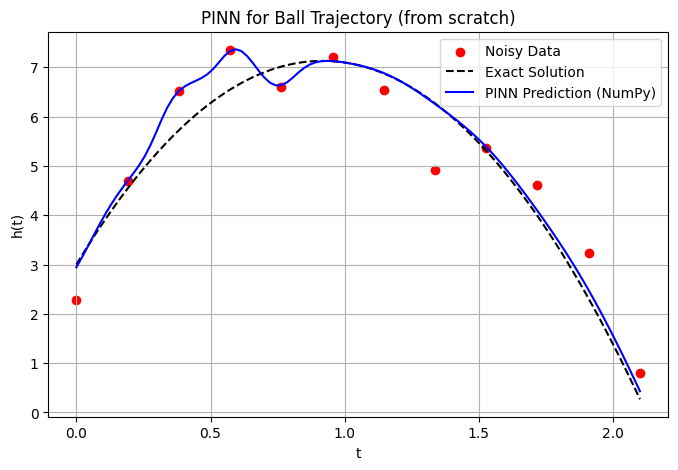

In [10]:
# evaluate the trained Model

t_plot = np.linspace(t_min, t_max, 100).reshape(-1, 1)
h_pred_plot = forward(params_pinn, t_plot, with_derivative=False)[0]
h_true_plot = true_solution(t_plot)

rmse = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
print(f"RMSE of noisy data vs exact solution : {rmse(h_data_noisy, h_data_exact):.3f} m")
print(f"RMSE of PINN prediction vs exact     : {rmse(h_pred_plot, h_true_plot):.3f} m")

plt.figure(figsize=(8, 5))
plt.scatter(t_data, h_data_noisy, color='red', label='Noisy Data')
plt.plot(t_plot, h_true_plot, 'k--', label='Exact Solution')
plt.plot(t_plot, h_pred_plot, 'b', label='PINN Prediction (NumPy)')
plt.xlabel('t')
plt.ylabel('h(t)')
plt.legend()
plt.title('PINN for Ball Trajectory (from scratch)')
plt.grid(True)
plt.show()

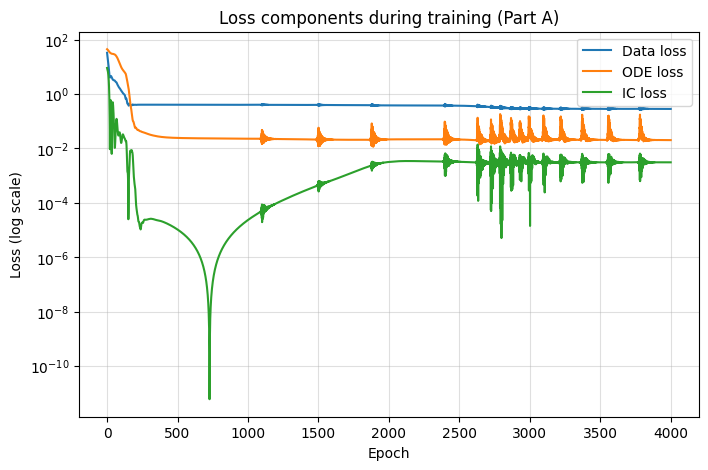

In [11]:
plt.figure(figsize=(8, 5))
plt.semilogy(hist_pinn[:, 1], label='Data loss')
plt.semilogy(hist_pinn[:, 2], label='ODE loss')
plt.semilogy(hist_pinn[:, 3], label='IC loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (log scale)')
plt.title('Loss components during training (Part A)')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**What to notice.** The ODE and initial-condition losses become very small, so the network satisfies the physics *at the points where we checked it*. The data loss stays well above zero, around 0.29, and that is the point: the measurements have noise of variance $0.7^2=0.49$, and the network refuses to chase all of it.

Still, the fitted curve is only a little closer to the truth than the raw data is. The reason is the next section.

## A10. Extension: check the physics at more points than we have data

Previously, the ODE loss is evaluated only at the 12 measurement times. Between those times nothing forces the network to follow the equation, so it has room to wiggle. The data are noisy, so the wiggles follow the noise.

Physics has an advantage over data here: we can evaluate the ODE residual at any time we like, with no measurement needed. Let us enforce it at 50 evenly spaced times (these are usually called *collocation points*) and keep the 12 data points for the data loss.

We also train a "data only" network (the ODE and IC weights set to zero) as the baseline to compare against.

Noisy data (reference)             RMSE = 0.677 m
Data only (no physics)             RMSE = 0.686 m
PINN, physics at 10 data times     RMSE = 0.309 m
PINN, physics at 50 points         RMSE = 0.096 m


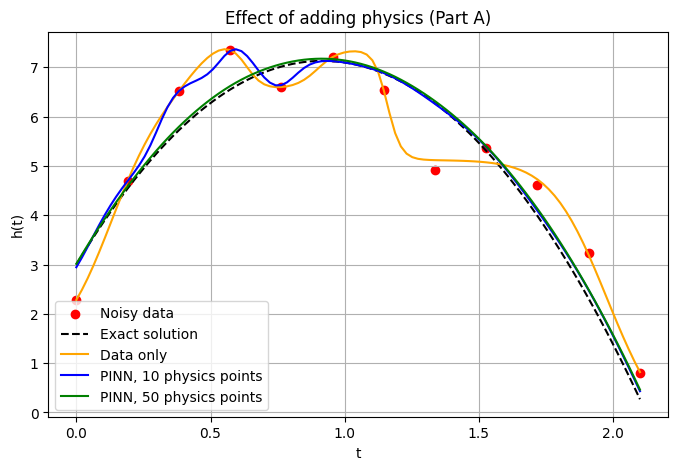

In [12]:
t_colloc = np.linspace(t_min, t_max, 50).reshape(-1, 1)

params_dense, hist_dense = train(lambda_data, lambda_ode, lambda_ic, t_ode=t_colloc, verbose=False)
params_data_only, hist_data_only = train(1.0, 0.0, 0.0, verbose=False)

results = {
    "Noisy data (reference)": None,
    "Data only (no physics)": forward(params_data_only, t_plot, with_derivative=False)[0],
    "PINN, physics at 10 data times": h_pred_plot,
    "PINN, physics at 50 points": forward(params_dense, t_plot, with_derivative=False)[0],
}
for name, pred in results.items():
    if pred is None:
        print(f"{name:34s} RMSE = {rmse(h_data_noisy, h_data_exact):.3f} m")
    else:
        print(f"{name:34s} RMSE = {rmse(pred, h_true_plot):.3f} m")

plt.figure(figsize=(8, 5))
plt.scatter(t_data, h_data_noisy, color='red', label='Noisy data')
plt.plot(t_plot, h_true_plot, 'k--', label='Exact solution')
plt.plot(t_plot, results["Data only (no physics)"], color='orange', label='Data only')
plt.plot(t_plot, results["PINN, physics at 10 data times"], 'b', label='PINN, 10 physics points')
plt.plot(t_plot, results["PINN, physics at 50 points"], 'g', label='PINN, 50 physics points')
plt.xlabel('t'); plt.ylabel('h(t)')
plt.title('Effect of adding physics (Part A)')
plt.legend(); plt.grid(True); plt.show()

The numbers above show how much the physics helps. Using physics only at the data times gives a modest gain over the data-only fit. Using it at 50 points gives a much smaller error, because the curve is now held to the equation across the whole interval, not just at 12 spots.

This is a result from one noise draw and one initialisation, so treat the exact numbers as an illustration and not a benchmark. We repeated the 50-point run with a few different random initialisations while testing and the error stayed close to the same value.

**End of Part A.** We built a working PINN with nothing but NumPy: a forward pass, its time derivative, hand-derived gradients checked against finite differences, and an optimiser. Part B repeats the problem with PyTorch, which does the derivative work automatically.

---
---
# Part B: PyTorch and more advanced tools

Here we do the same problem with PyTorch. Two things become automatic:

1. **Automatic differentiation (autograd)** computes $d\hat h/dt$ for the ODE loss. We no longer write the chain-rule formulas of section 4.6.
2. **Backpropagation** for the whole loss, including the derivative of that derivative. The long derivation in section A5 collapses into `loss.backward()`.

> **Run this part in an environment with PyTorch installed.** Install with `pip install torch` or use Google Colab, which already has it.

## B1. Imports
`torch` is the main library, `torch.nn` holds the layer building blocks, and NumPy and Matplotlib handle data and plotting.

In [13]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

## B2. Synthetic measurements
The same data recipe as in A2, now converted to PyTorch tensors of dtype `float32` and shape `(N, 1)`. The code below is the newsletter's code unchanged.

In [14]:
# 1. generate synthetic data

# Physics parameters
g = 9.81        # acceleration due to gravity
h0 = 3.0      # initial height
v0 = 9.0      # initial velocity

# True (analytical) solution h(t) = h0 + v0*t - 0.5*g*t^2
def true_solution(t):
    return h0 + v0*t - 0.5*g*(t**2)

# generate some time points
t_min, t_max = 0.0, 2.1
N_data = 12
t_data = np.linspace(t_min, t_max, N_data)

# generate synthetic "experimental" heights with noise
np.random.seed(108)
noise_level = 0.7
h_data_exact = true_solution(t_data)
h_data_noisy = h_data_exact + noise_level*np.random.randn(N_data)

# convert to PyTorch tensors
t_data_tensor = torch.tensor(t_data, dtype=torch.float32).view(-1, 1)
h_data_tensor = torch.tensor(h_data_noisy, dtype=torch.float32).view(-1, 1)

## B3. The network
A fully connected network with two hidden layers of 20 neurons and $\tanh$ activations, which is the same architecture as Part A. `nn.Sequential` stacks the layers, and `nn.Linear(a, b)` computes $\mathbf x\mathbf W+\mathbf b$ with weights initialised by PyTorch's default rule. The `forward` method is what runs when we call `model(t)`.

In [15]:
# 2. small feed-forward neural network for h(t)
class PINN(nn.Module):
    def __init__(self, n_hidden=20):
        super(PINN, self).__init__()
        # A simple MLP with 2 hidden layers
        self.net = nn.Sequential(
            nn.Linear(1, n_hidden),
            nn.Tanh(),
            nn.Linear(n_hidden, n_hidden),
            nn.Tanh(),
            nn.Linear(n_hidden, 1)
        )

    def forward(self, t):
        # forward pass: input shape (batch_size, 1) -> output shape (batch_size, 1)
        return self.net(t)

If we create a model without fixing a random seed, so every run starts from different weights and gives slightly different numbers. For a notebook that others will rerun, we fix the seed first.

In [16]:
# random seed so results are repeatable
torch.manual_seed(0)

# initialize the model
model = PINN(n_hidden=20)

## B4. Automatic differentiation helper
`torch.autograd.grad(y, x, ...)` returns $\partial y/\partial x$. Two arguments deserve a note:

* `grad_outputs=torch.ones_like(y)`: `y` has one entry per time point. Passing a vector of ones asks for the derivative of each entry with respect to its own time point, which is what we want since each $\hat h(t_i)$ only depends on $t_i$.
* `create_graph=True`: this tells PyTorch to keep a record of how the derivative was computed. We need that because the ODE loss contains $d\hat h/dt$, and in training we differentiate the loss with respect to the weights, which means differentiating through this derivative. Without it, the gradient with respect to the weights would be wrong or missing.

In [17]:
# 3.  Automatic Diff

def derivative(y, x):
    # computes dy/dx using PyTorch's autograd.
    # y and x must be tensors with requires_grad=True for x.
    return torch.autograd.grad(
        y, x,
        grad_outputs=torch.ones_like(y),
        create_graph=True
    )[0]

## B5. The loss components
These are the three terms of section 4.4.

* `physics_loss` marks the time tensor with `requires_grad_(True)` so PyTorch can differentiate with respect to it, computes $d\hat h/dt$ through `derivative`, and compares it with $v_0-g\,t$.
* `initial_condition_loss` evaluates the network at $t=0$ and compares with $h_0$.
* `data_loss` is the MSE against the noisy measurements.

In [18]:
# 4.  Loss Components (PINN)


# We have:
#    (1) data loss (fit noisy data)
#    (2) ODE loss: dh/dt = v0 - g * t
#    (3) initial condition loss: h(0) = h0

def physics_loss(model, t):
    # compare d(h_pred)/dt with the known expression (v0 - g t).

    # t must have requires_grad = True for autograd to work
    t.requires_grad_(True)

    h_pred = model(t)
    dh_dt_pred = derivative(h_pred, t)

    # for each t, physics says dh/dt = v0 - g * t
    dh_dt_true = v0 - g * t

    loss_ode = torch.mean((dh_dt_pred - dh_dt_true)**2)
    return loss_ode

def initial_condition_loss(model):
    # enforce h(0) = h0.

    # evaluate at t=0
    t0 = torch.zeros(1, 1, dtype=torch.float32, requires_grad=False)
    h0_pred = model(t0)
    return (h0_pred - h0).pow(2).mean()

def data_loss(model, t_data, h_data):
    # MSE between predicted h(t_i) and noisy measurements h_data.
    h_pred = model(t_data)
    return torch.mean((h_pred - h_data)**2)

## B6. Training set-up

In [19]:
# 5. training Setup

optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# hyperparameters for weighting the loss terms
lambda_data = 2.0
lambda_ode  = 2.0
lambda_ic   = 2.0

# logging purposes
num_epochs = 4000
print_every = 200

## B7. Training loop
Each epoch does five things:

1. `optimizer.zero_grad()` clears the gradients from the previous step (PyTorch adds new gradients to old ones by default).
2. Compute the three losses and combine them with the weights.
3. `loss.backward()` computes the gradient of the total loss with respect to every weight. This one line replaces the hand-written backpropagation of Part A.
4. `optimizer.step()` updates the weights.
5. Print the losses every 200 epochs.

In [20]:
# 6. training Loop

model.train()
for epoch in range(num_epochs):
    optimizer.zero_grad()

    # compute losses
    l_data = data_loss(model, t_data_tensor, h_data_tensor)
    l_ode  = physics_loss(model, t_data_tensor)
    l_ic   = initial_condition_loss(model)

    # combined loss
    loss = lambda_data * l_data + lambda_ode * l_ode + lambda_ic * l_ic

    # backprop
    loss.backward()
    optimizer.step()

    # print progress
    if (epoch+1) % print_every == 0:
        print(f"Epoch {epoch+1}/{num_epochs}, "
              f"Total Loss = {loss.item():.6f}, "
              f"Data Loss = {l_data.item():.6f}, "
              f"ODE Loss = {l_ode.item():.6f}, "
              f"IC Loss = {l_ic.item():.6f}")

Epoch 200/4000, Total Loss = 1.105246, Data Loss = 0.402287, ODE Loss = 0.148121, IC Loss = 0.002215
Epoch 400/4000, Total Loss = 0.825755, Data Loss = 0.381363, ODE Loss = 0.027017, IC Loss = 0.004498
Epoch 600/4000, Total Loss = 0.814996, Data Loss = 0.382121, ODE Loss = 0.022154, IC Loss = 0.003224
Epoch 800/4000, Total Loss = 0.813877, Data Loss = 0.382378, ODE Loss = 0.021632, IC Loss = 0.002929
Epoch 1000/4000, Total Loss = 0.812901, Data Loss = 0.382202, ODE Loss = 0.021336, IC Loss = 0.002912
Epoch 1200/4000, Total Loss = 0.811835, Data Loss = 0.381840, ODE Loss = 0.021136, IC Loss = 0.002942
Epoch 1400/4000, Total Loss = 0.810630, Data Loss = 0.381299, ODE Loss = 0.021028, IC Loss = 0.002988
Epoch 1600/4000, Total Loss = 0.809335, Data Loss = 0.380591, ODE Loss = 0.021025, IC Loss = 0.003051
Epoch 1800/4000, Total Loss = 0.808189, Data Loss = 0.379864, ODE Loss = 0.021114, IC Loss = 0.003117
Epoch 2000/4000, Total Loss = 0.807435, Data Loss = 0.379326, ODE Loss = 0.021230, IC 

## B8. Evaluating the trained model
We switch to evaluation mode, predict on a fine time grid, and compare with the exact solution and the noisy data. `.detach().numpy()` converts the result from a tensor that tracks gradients into an ordinary NumPy array for plotting.

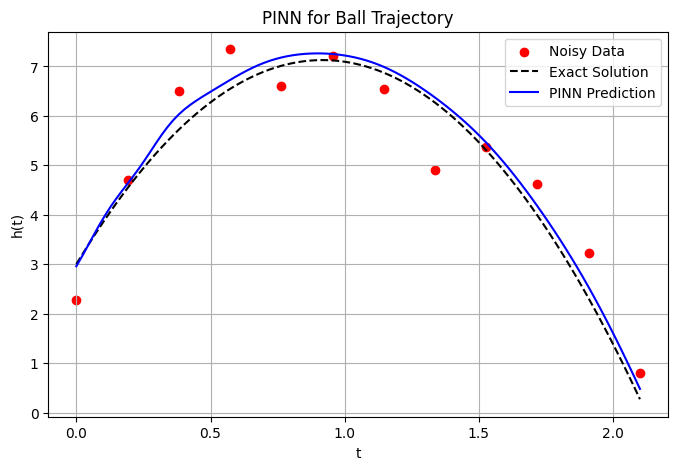

In [21]:
# 7. evaluate the trained Model

model.eval()
t_plot = np.linspace(t_min, t_max, 100).reshape(-1, 1).astype(np.float32)
t_plot_tensor = torch.tensor(t_plot, requires_grad=True)
h_pred_plot = model(t_plot_tensor).detach().numpy()

# true solution (for comparison)
h_true_plot = true_solution(t_plot)

# plot results
plt.figure(figsize=(8, 5))
plt.scatter(t_data, h_data_noisy, color='red', label='Noisy Data')
plt.plot(t_plot, h_true_plot, 'k--', label='Exact Solution')
plt.plot(t_plot, h_pred_plot, 'b', label='PINN Prediction')
plt.xlabel('t')
plt.ylabel('h(t)')
plt.legend()
plt.title('PINN for Ball Trajectory')
plt.grid(True)
plt.show()

The PINN curve should follow the overall arc of the dashed exact curve instead of chasing every red dot. Some mismatch can remain, especially near $t=0$, because the ODE is only enforced at the 12 data times (see the discussion in A10). The next sections show how to improve on that.

---
## Advanced additions

Everything below is new relative to the newsletter. It uses a few tools beyond the basics and shows how to evaluate the model more carefully.

## B9. A reusable training function and an error metric
To run several experiments without copying the loop, we wrap training in one function. It takes the loss weights and the set of times where the ODE is enforced (`t_ode`), and returns the trained model and a loss history. We also define the RMSE against the exact solution.

The data points are still the same 12 noisy measurements. The only difference from B7 is that the ODE loss may use a different set of times, which can be as dense as we like because physics needs no measurements.

In [22]:
def rmse_vs_exact(m, n=200):
    t_eval = torch.linspace(t_min, t_max, n).view(-1, 1)
    with torch.no_grad():
        pred = m(t_eval).numpy()
    return float(np.sqrt(np.mean((pred - true_solution(t_eval.numpy())) ** 2)))


def train_pinn(lam_data, lam_ode, lam_ic, t_ode=None, epochs=4000, lr=0.01, seed=0):
    torch.manual_seed(seed)
    m = PINN(n_hidden=20)
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    t_phys = (t_data_tensor if t_ode is None else t_ode).clone().detach()
    history = []
    for _ in range(epochs):
        opt.zero_grad()
        l_d = data_loss(m, t_data_tensor, h_data_tensor)
        l_o = physics_loss(m, t_phys)
        l_i = initial_condition_loss(m)
        total = lam_data * l_d + lam_ode * l_o + lam_ic * l_i
        total.backward()
        opt.step()
        history.append([total.item(), l_d.item(), l_o.item(), l_i.item()])
    return m, np.array(history)

## B10. Does the physics actually help? Three-way comparison
We train three versions with the same seed and compare their RMSE against the exact solution:

1. **Data only**: $\lambda_{\text{ODE}}=\lambda_{\text{IC}}=0$. Ordinary curve fitting.
2. **PINN**: physics enforced at the ten data times.
3. **PINN with 50 collocation points**: physics enforced at 50 evenly spaced times.

Noisy data vs exact                  : RMSE = 0.677 m
Data only                            : RMSE = 0.719 m
PINN, physics at 10 data times       : RMSE = 0.172 m
PINN, physics at 50 collocation pts  : RMSE = 0.096 m


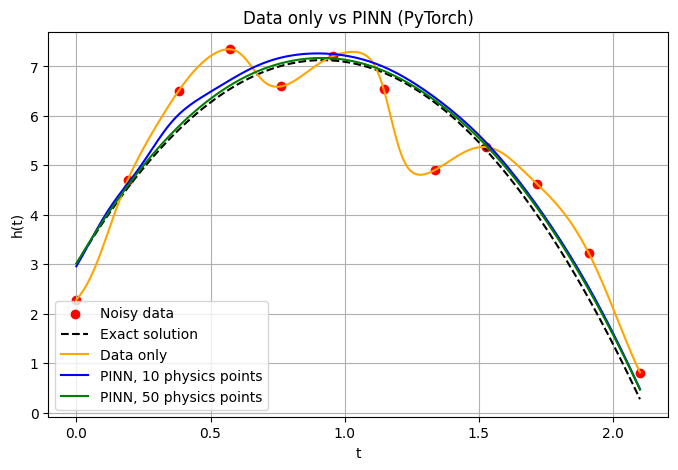

In [23]:
t_colloc_t = torch.linspace(t_min, t_max, 50).view(-1, 1)

model_data_only, _ = train_pinn(1.0, 0.0, 0.0)
model_pinn_10, _ = train_pinn(2.0, 2.0, 2.0)
model_pinn_50, hist_50 = train_pinn(2.0, 2.0, 2.0, t_ode=t_colloc_t)

print(f"Noisy data vs exact                  : RMSE = {np.sqrt(np.mean((h_data_noisy - h_data_exact)**2)):.3f} m")
print(f"Data only                            : RMSE = {rmse_vs_exact(model_data_only):.3f} m")
print(f"PINN, physics at 10 data times       : RMSE = {rmse_vs_exact(model_pinn_10):.3f} m")
print(f"PINN, physics at 50 collocation pts  : RMSE = {rmse_vs_exact(model_pinn_50):.3f} m")

t_eval = torch.linspace(t_min, t_max, 200).view(-1, 1)
plt.figure(figsize=(8, 5))
plt.scatter(t_data, h_data_noisy, color='red', label='Noisy data')
plt.plot(t_eval, true_solution(t_eval.numpy()), 'k--', label='Exact solution')
with torch.no_grad():
    plt.plot(t_eval, model_data_only(t_eval), color='orange', label='Data only')
    plt.plot(t_eval, model_pinn_10(t_eval), 'b', label='PINN, 10 physics points')
    plt.plot(t_eval, model_pinn_50(t_eval), 'g', label='PINN, 50 physics points')
plt.xlabel('t'); plt.ylabel('h(t)')
plt.title('Data only vs PINN (PyTorch)')
plt.legend(); plt.grid(True); plt.show()

In the NumPy run of Part A the ordering was "data only" worse than "10 physics points", which was worse than "50 physics points". You should see the same general pattern here. The exact numbers will differ from Part A: the two parts use different random initial weights, and float32 in PyTorch versus float64 in NumPy also changes the later digits.

## B11. Sensitivity to the loss weights
The weights $\lambda$ decide whose side the network takes when data and physics disagree. We keep $\lambda_{\text{data}}=1$ and $\lambda_{\text{IC}}=1$ and sweep the ODE weight over several orders of magnitude, using 50 collocation points.

Because the underlying data are noisy and the physics here is exactly right (no drag, no wind), we expect the error to drop as $\lambda_{\text{ODE}}$ grows. In a real problem where the equation is only approximate, you would not want to push it too high.

lambda_ODE =    0.00  ->  RMSE = 0.714 m
lambda_ODE =    0.01  ->  RMSE = 0.500 m
lambda_ODE =    0.10  ->  RMSE = 0.247 m
lambda_ODE =    1.00  ->  RMSE = 0.097 m
lambda_ODE =   10.00  ->  RMSE = 0.056 m
lambda_ODE =  100.00  ->  RMSE = 0.049 m


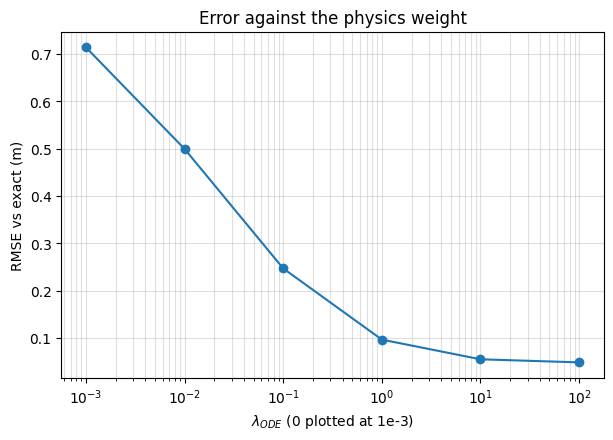

In [24]:
lam_values = [0.0, 0.01, 0.1, 1.0, 10.0, 100.0]
sweep_rmse = []
for lam in lam_values:
    m, _ = train_pinn(1.0, lam, 1.0, t_ode=t_colloc_t)
    sweep_rmse.append(rmse_vs_exact(m))
    print(f"lambda_ODE = {lam:7.2f}  ->  RMSE = {sweep_rmse[-1]:.3f} m")

plt.figure(figsize=(7, 4.5))
plt.semilogx([max(l, 1e-3) for l in lam_values], sweep_rmse, 'o-')
plt.xlabel(r'$\lambda_{ODE}$ (0 plotted at 1e-3)')
plt.ylabel('RMSE vs exact (m)')
plt.title('Error against the physics weight')
plt.grid(True, which='both', alpha=0.4)
plt.show()

## B12. A second optimiser: Adam followed by L-BFGS
Adam is robust but slow to settle precisely. L-BFGS is a quasi-Newton method: it builds an approximation of the curvature of the loss from recent gradients and takes bigger, better-aimed steps. It is much used in PINN work for the final polish, because the loss functions are smooth and the problems are small.

L-BFGS in PyTorch needs a **closure**, a function that recomputes the loss and its gradients on demand, because the optimiser may need to evaluate the loss several times within one step.

We start from the 50-point model trained with Adam and polish it.

In [25]:
import copy
model_lbfgs = copy.deepcopy(model_pinn_50)
opt_lbfgs = torch.optim.LBFGS(model_lbfgs.parameters(), lr=1.0, max_iter=500,
                              tolerance_grad=1e-9, tolerance_change=1e-12,
                              line_search_fn="strong_wolfe")
t_phys = t_colloc_t.clone().detach()

def closure():
    opt_lbfgs.zero_grad()
    total = (2.0 * data_loss(model_lbfgs, t_data_tensor, h_data_tensor)
             + 2.0 * physics_loss(model_lbfgs, t_phys)
             + 2.0 * initial_condition_loss(model_lbfgs))
    total.backward()
    return total

print(f"RMSE before L-BFGS: {rmse_vs_exact(model_lbfgs):.4f} m")
opt_lbfgs.step(closure)
print(f"RMSE after  L-BFGS: {rmse_vs_exact(model_lbfgs):.4f} m")

RMSE before L-BFGS: 0.0962 m
RMSE after  L-BFGS: 0.0963 m


With only 12 noisy data points, the limit on accuracy is the noise in the data and not the optimiser, so do not expect L-BFGS to produce a dramatic drop in RMSE here. What it does improve is how fully the loss is minimised. On problems with clean data or with equations alone, the benefit is larger.

## B13. Computing $dh/dt$ with `torch.func`
In B4 we used `torch.autograd.grad`. PyTorch also offers a functional style in `torch.func` where you write a function for a *single* input and then ask for its derivative and vectorise it across the batch. This is the style used in more advanced code, and it scales better when you move to second derivatives or PDEs with several inputs.

* `jacrev(f)` returns a function that computes the derivative of `f`.
* `vmap(...)` applies that function across all points in the batch at once.

Below we compute $d\hat h/dt$ both ways and check that they agree.

In [26]:
from torch.func import jacrev, vmap

def h_scalar(t_scalar):
    # network value for one time point: input shape (1,), output shape (1,)
    return model(t_scalar.view(1, 1)).view(1)

dh_dt_func = vmap(jacrev(h_scalar))              # derivative at every time point
t_test = torch.linspace(t_min, t_max, 8).view(-1, 1)

d_func = dh_dt_func(t_test.view(-1, 1)).view(-1)          # torch.func result
t_ag = t_test.clone().requires_grad_(True)
d_autograd = derivative(model(t_ag), t_ag).view(-1)       # autograd.grad result

print("max difference between the two methods:",
      float((d_func - d_autograd).abs().max()))
print("exact derivative v0 - g t             :", (v0 - g * t_test.view(-1)).numpy().round(3))
print("network derivative (autograd)         :", d_autograd.detach().numpy().round(3))

max difference between the two methods: 7.152557373046875e-07
exact derivative v0 - g t             : [  9.      6.057   3.114   0.171  -2.772  -5.715  -8.658 -11.601]
network derivative (autograd)         : [ 9.0350e+00  8.0780e+00  3.0810e+00 -5.0000e-03 -2.9180e+00 -5.4180e+00
 -8.4090e+00 -1.1627e+01]


/tmp/ipykernel_3676/1821768576.py:15: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  float((d_func - d_autograd).abs().max()))


The two methods match to floating-point precision. The last two lines also show how close the trained network's slope is to the true velocity $v_0 - g\,t$, which is a useful sanity check on any PINN.

## B14. Plot the residual away from the training points
A low loss at the training points does not prove the network satisfies the ODE everywhere. A direct test is to evaluate the **ODE residual** $\hat h'(t) - (v_0-g\,t)$ on a fine grid that includes times the network never saw during training. Here we compare the model (physics at 10 points) with the 50-point model.

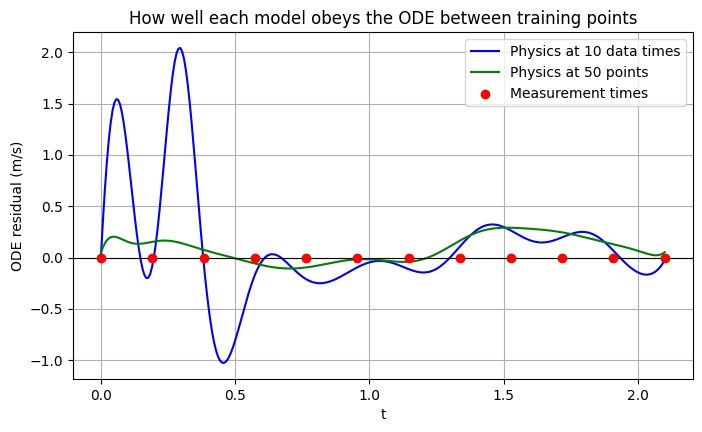

In [27]:
def ode_residual(m, t_vals):
    t_in = t_vals.clone().detach().requires_grad_(True)
    dh = derivative(m(t_in), t_in)
    return (dh - (v0 - g * t_in)).detach().numpy().ravel()

t_dense = torch.linspace(t_min, t_max, 300).view(-1, 1)
plt.figure(figsize=(8, 4.5))
plt.plot(t_dense, ode_residual(model_pinn_10, t_dense), 'b', label='Physics at 10 data times')
plt.plot(t_dense, ode_residual(model_pinn_50, t_dense), 'g', label='Physics at 50 points')
plt.scatter(t_data, np.zeros_like(t_data), color='red', zorder=3, label='Measurement times')
plt.axhline(0, color='k', lw=0.8)
plt.xlabel('t'); plt.ylabel('ODE residual (m/s)')
plt.title('How well each model obeys the ODE between training points')
plt.legend(); plt.grid(True); plt.show()

The residual of the 10-point model is only forced towards zero at the measurement times, so it is free to drift in between. The 50-point model is checked much more densely, so its residual should stay small across the whole interval. That is the likely reason for its better accuracy.

## B15. Optional: the same problem with DeepXDE
DeepXDE is a library built specifically for PINNs. You describe the ODE, the initial condition and the data, and the library handles the network, the sampling of points and the training loop. This is the quickest route once you know what is happening inside, which is why Parts A and B come first.

This cell is optional. It only runs if DeepXDE is installed (`pip install deepxde`). We use the first-order form $dh/dt = v_0 - g\,t$ with $h(0)=h_0$ and add the 12 noisy measurements as extra data constraints.

*Library interfaces change between versions. If this cell raises an error, check the DeepXDE documentation for the version you have. The rest of the notebook does not depend on it.*

In [28]:
!pip install deepxde

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 195.4/195.4 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 9.0 MB/s eta 0:00:00


In [29]:
try:
    import os

    os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
    import deepxde as dde
    import numpy as np

    def ode_system(t, h):
        dh_dt = dde.grad.jacobian(h, t)
        return dh_dt - (v0 - g * t)

    geom = dde.geometry.TimeDomain(t_min, t_max)


    ic = dde.icbc.IC(geom, lambda x: h0, lambda x, on_initial: on_initial)
    observe = dde.icbc.PointSetBC(t_data.reshape(-1, 1), h_data_noisy.reshape(-1, 1))

    data = dde.data.PDE(geom, ode_system, [ic, observe], num_domain=50, num_boundary=1)
    net = dde.nn.FNN([1, 20, 20, 1], "tanh", "Glorot normal")
    dde_model = dde.Model(data, net)
    dde_model.compile("adam", lr=0.01)
    dde_model.train(iterations=4000, display_every=1000)

    h_dde = dde_model.predict(t_plot)
    print("DeepXDE RMSE vs exact:", float(np.sqrt(np.mean((h_dde - true_solution(t_plot)) ** 2))))
except ImportError:
    print("DeepXDE is not installed, skipping this optional cell.")


No backend selected.
Finding available backend...
Found tensorflow
Using backend: tensorflow
Other supported backends: tensorflow.compat.v1, pytorch, jax, paddle.
paddle supports more examples now and is recommended.


Setting the default backend to "tensorflow". You can change it in the ~/.deepxde/config.json file or export the DDE_BACKEND environment variable. Valid options are: tensorflow.compat.v1, tensorflow, pytorch, jax, paddle (all lowercase)
Compiling model...
'compile' took 0.012915 s

Training model...



Cause: could not parse the source code of <function <lambda> at 0x7b76c09e1940>: no matching AST found among candidates:
# coding=utf-8
lambda x, on: np.array([on_boundary(x[i], on[i]) for i in range(len(x))])
# coding=utf-8
lambda x, on: np.array([on_boundary1(x[i], on[i]) for i in range(len(x))])
# coding=utf-8
lambda x, on: np.array([on_boundary2(x[i], on[i]) for i in range(len(x))])
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function <lambda> at 0x7b76c09e1940>: no matching AST found among candidates:
# coding=utf-8
lambda x, on: np.array([on_boundary(x[i], on[i]) for i in range(len(x))])
# coding=utf-8
lambda x, on: np.array([on_boundary1(x[i], on[i]) for i in range(len(x))])
# coding=utf-8
lambda x, on: np.array([on_boundary2(x[i], on[i]) for i in range(len(x))])
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Step      Train loss                        Test loss                         Test metric
0         [3.37e+01, 9.00e+00, 2.36e+01]    [3.37e+01, 9.00e+00, 2.36e+01]    []  
1000      [2.29e-02, 2.03e-04, 4.03e-01]    [2.29e-02, 2.03e-04, 4.03e-01]    []  
2000      [2.19e-02, 1.97e-04, 4.03e-01]    [2.19e-02, 1.97e-04, 4.03e-01]    []  
3000      [2.22e-02, 1.93e-04, 4.02e-01]    [2.22e-02, 1.93e-04, 4.02e-01]    []  
4000      [2.33e-02, 1.69e-04, 4.01e-01]    [2.33e-02, 1.69e-04, 4.01e-01]    []  

Best model

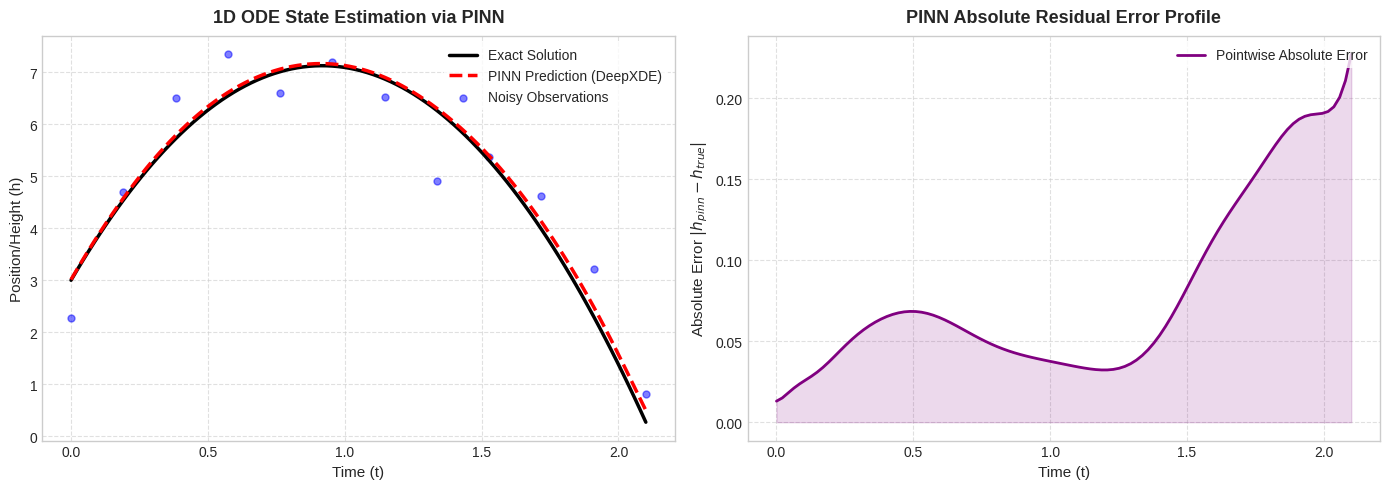

In [30]:
import matplotlib.pyplot as plt
import numpy as np


plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# plot 1: trajectory comparison (True vs. PINN vs. Noisy Observations)
ax1.plot(t_plot, true_solution(t_plot), 'k-', linewidth=2.5, label='Exact Solution')
ax1.plot(t_plot, h_dde, 'r--', linewidth=2.5, label='PINN Prediction (DeepXDE)')
ax1.scatter(t_data, h_data_noisy, color='blue', alpha=0.5, s=25, marker='o', label='Noisy Observations')

ax1.set_title('1D ODE State Estimation via PINN', fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel('Time (t)', fontsize=11)
ax1.set_ylabel('Position/Height (h)', fontsize=11)
ax1.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')
ax1.grid(True, linestyle='--', alpha=0.6)

# plot 2: Prediction Absolute Error Distribution
absolute_error = np.abs(h_dde.flatten() - true_solution(t_plot).flatten())

ax2.plot(t_plot, absolute_error, color='purple', linewidth=2, label='Pointwise Absolute Error')
ax2.fill_between(t_plot.flatten(), absolute_error, color='purple', alpha=0.15)

ax2.set_title('PINN Absolute Residual Error Profile', fontsize=13, fontweight='bold', pad=10)
ax2.set_xlabel('Time (t)', fontsize=11)
ax2.set_ylabel('Absolute Error $|h_{pinn} - h_{true}|$', fontsize=11)
ax2.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


---
# Summary

| | Part A (NumPy) | Part B (PyTorch) |
|---|---|---|
| Derivative of the network | Chain rule written out by hand | `torch.autograd.grad` or `torch.func` |
| Gradient of the loss | Derived and coded by hand, checked against finite differences | `loss.backward()` |
| Optimiser | Adam written from the equations | `torch.optim.Adam`, then `LBFGS` |
| Good for | Understanding every step | Faster experiments, larger models, other optimisers |

**What the experiments showed**

* A network trained on the data alone follows the noise.
* Adding the ODE and the initial condition to the loss pulls the curve towards the physical trajectory.
* Where the physics is enforced matters. Checking the ODE only at the measurement times leaves room for error in between. Checking it on a denser grid gives a clearly better fit.
* The weight on the physics term controls the balance between trusting the equation and trusting the data. When the equation is exact, a larger weight helps. When it is only approximate, the data should keep a say.

**Limits of this example**

* The ODE is simple and has a known exact answer, so we could measure the error directly. In real problems you usually cannot.
* One noise draw and one random start were used. A proper study would repeat this over many seeds and report averages.
* A first-order ODE in one variable is the easiest PINN case. Partial differential equations, stiff problems, and problems with several scales need extra care (loss weighting, time-marching, better architectures).


# References

1. M. Raissi, P. Perdikaris, G. E. Karniadakis, *Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations*, Journal of Computational Physics, 378, 686–707 (2019).
2. D. P. Kingma and J. Ba, *Adam: A method for stochastic optimization*, ICLR (2015).
3. L. Lu, X. Meng, Z. Mao, G. E. Karniadakis, *DeepXDE: A deep learning library for solving differential equations*, SIAM Review, 63(1), 208–228 (2021).